In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.layers import Flatten, Dense, LSTM, Dropout, BatchNormalization, Conv1D, Layer, Activation, Add, Multiply, MaxPooling1D, AveragePooling1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import LeakyReLU, Input, UpSampling1D


In [ ]:
data = pd.read_csv("/content/drive/MyDrive/Datasets/har70plus/HAR70_FDC4300.csv")

label = LabelEncoder()
data['Labels'] = label.fit_transform(data['activityID'])
data.head()


,acc_x1,acc_y1,acc_z1,acc_x2,acc_y2,acc_z2,activityID,subjectID,Labels
0,-0.999023,-0.063477,0.140625,-0.980469,-0.112061,-0.048096,6,1,4
1,-0.980225,-0.079346,0.140625,-0.961182,-0.121582,-0.051758,6,1,4
2,-0.950195,-0.076416,0.140625,-0.949463,-0.080566,-0.067139,6,1,4
3,-0.954834,-0.059082,0.140381,-0.957520,-0.046143,-0.050781,6,1,4
4,-0.972412,-0.042969,0.142822,-0.977051,-0.023682,-0.026611,6,1,4


In [ ]:
X = data[['acc_x1', "acc_y1", 'acc_z1', 'acc_x2', "acc_y2", 'acc_z2']]
Y = data['Labels']

In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
Scaled_X = pd.DataFrame(X, columns=['acc_x1', "acc_y1", 'acc_z1', 'acc_x2', "acc_y2", 'acc_z2'])
Scaled_X["Labels"] = Y.values
Scaled_X.head()


,acc_x1,acc_y1,acc_z1,acc_x2,acc_y2,acc_z2,Labels
0,-0.601701,-0.127676,0.138049,-0.672898,-0.409844,0.842167,4
1,-0.539218,-0.272147,0.138049,-0.627732,-0.469954,0.834451,4
2,-0.439400,-0.245472,0.138049,-0.600289,-0.211005,0.802044,4
3,-0.454820,-0.087664,0.137528,-0.619157,0.006319,0.836510,4
4,-0.513248,0.059028,0.142744,-0.664894,0.148124,0.887434,4


In [ ]:
import scipy.stats as stats

In [ ]:
frame_size = 50
overlap_size = 5

In [ ]:
from re import M
def get_frames(data, frame_size, overlap_size):
  frames = []
  labels = []
  n_features = 6
  for i in range(0, len(data) - frame_size, overlap_size):
    x = data["acc_x1"].values[i: i + frame_size]
    y = data["acc_y1"].values[i: i + frame_size]
    z = data["acc_z1"].values[i: i + frame_size]
    x2 = data["acc_x2"].values[i: i + frame_size]
    y2 = data["acc_y2"].values[i: i + frame_size]
    z2= data["acc_z2"].values[i: i + frame_size]


    label = stats.mode(data["Labels"][i: i + frame_size])[0]
    frames.append([x, y, z, x2, y2, z2])
    labels.append(label)
  frames = np.array(frames).reshape(-1, frame_size, n_features)
  labels = np.array(labels)
  return frames, labels


In [ ]:
X_data, Y_data = get_frames(Scaled_X, frame_size, overlap_size)

In [ ]:
X_data.shape, Y_data.shape

((6010, 50, 6), (6010,))

In [ ]:
print("NaNs in X:", np.isnan(X_data).sum())
print("Infs in X:", np.isinf(X_data).sum())

NaNs in X: 0
Infs in X: 0


In [ ]:
print("NaNs in Y_train:", np.isnan(Y_data).sum())
print("Infs in Y_train:", np.isinf(Y_data).sum())
print("Unique labels:", np.unique(Y_data))

NaNs in Y_train: 0
Infs in Y_train: 0
Unique labels: [0 1 2 3 4 5 6]


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X_data, Y_data, test_size=0.2, random_state=42)
X_val, X_test, Y_val, Y_test = train_test_split(X_test, Y_test, test_size=0.75, random_state=42)

In [ ]:
X_train.shape, Y_train.shape, X_test.shape, Y_test.shape

((4808, 50, 6), (4808,), (902, 50, 6), (902,))

In [ ]:
X_train.dtype

dtype('float64')

In [ ]:
from tensorflow.keras.layers import Layer
from tensorflow.keras import backend as K

class SelfAttention(Layer):
    def __init__(self, attention_units):
        super(SelfAttention, self).__init__()
        self.attention_units = attention_units

    def build(self, input_shape):
        self.W_q = self.add_weight(shape=(input_shape[-1], self.attention_units),
                                   initializer='glorot_uniform', trainable=True)
        self.W_k = self.add_weight(shape=(input_shape[-1], self.attention_units),
                                   initializer='glorot_uniform', trainable=True)
        self.W_v = self.add_weight(shape=(input_shape[-1], self.attention_units),
                                   initializer='glorot_uniform', trainable=True)
        super(SelfAttention, self).build(input_shape)

    def call(self, inputs):
        Q = tf.matmul(inputs, self.W_q)
        K_ = tf.matmul(inputs, self.W_k)
        V = tf.matmul(inputs, self.W_v)

        scores = tf.matmul(Q, K_, transpose_b=True)
        d_k = tf.cast(tf.shape(K_)[-1], tf.float32)
        scaled_scores = scores / (tf.math.sqrt(d_k))

        weights = tf.nn.softmax(scaled_scores, axis=-1)
        output = tf.matmul(weights, V)

        return output

In [ ]:
from tensorflow.keras.layers import GlobalAveragePooling1D, Reshape
input_layer = Input(shape=(X_train.shape[1], X_train.shape[2]))

# Encoder
x = Conv1D(64, kernel_size=3, activation= 'relu', padding='same')(input_layer)
x = MaxPooling1D(pool_size=2, padding='same')(x)
x = Conv1D(32, kernel_size=3, activation='relu', padding='same')(x)
x = BatchNormalization()(x)

bottleneck = AveragePooling1D(pool_size=2)(x)

# Decoder
x = BatchNormalization()(bottleneck)
x = Conv1D(32, kernel_size=3, activation='relu', padding='same')(x)
x = UpSampling1D(size=2)(x)
x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(x)

x = SelfAttention(attention_units = 64)(x)

x = LSTM(64, return_sequences=True)(x)
x = LSTM(32, return_sequences=True)(x)

x = Flatten()(x)
x = Dense(32, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(0.01))(x)
x = Dense(16, activation ='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01))(x)
x = Dropout(0.2)(x)
x = Dense(8, activation = 'relu', kernel_regularizer=tf.keras.regularizers.l2(0.01))(x)
output_layer = Dense(7, activation = 'softmax')(x)

model = Model(input_layer, output_layer)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 50, 6)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 50, 64)         │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 25, 32)         │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 25, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling1d               │ (None, 12, 32)         │             0 │
│ (AveragePooling1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 12, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 12, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d (UpSampling1D)    │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 24, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ self_attention (SelfAttention)  │ (None, 24, 64)         │        12,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 24, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 24, 32)         │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        24,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,023 (390.71 KB)

 Trainable params: 99,895 (390.21 KB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
# Compile the model
model.compile(optimizer='rmsprop', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Fit the model
history = model.fit(X_train, Y_train, epochs=70, batch_size=32, validation_data=(X_val, Y_val), verbose=1)


Epoch 1/70
151/151 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.2637 - loss: 2.1888 - val_accuracy: 0.2233 - val_loss: 1.9383
Epoch 2/70
151/151 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.5533 - loss: 1.2890 - val_accuracy: 0.7067 - val_loss: 0.9902
Epoch 3/70
151/151 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6618 - loss: 0.9794 - val_accuracy: 0.5567 - val_loss: 2.6569
Epoch 4/70
151/151 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7269 - loss: 0.8567 - val_accuracy: 0.7900 - val_loss: 0.7452
Epoch 5/70
151/151 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7610 - loss: 0.7784 - val_accuracy: 0.8067 - val_loss: 0.6321
Epoch 6/70
151/151 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7820 - loss: 0.6829 - val_accuracy: 0.8333 - val_loss: 0.5738
Epoch 7/70
151/151 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8021 - loss: 0.6319 - val_accuracy: 0.8067 - val_loss: 0.6483
Epoch 8/70
151/151 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8238 - loss: 0.6213 - val_accu

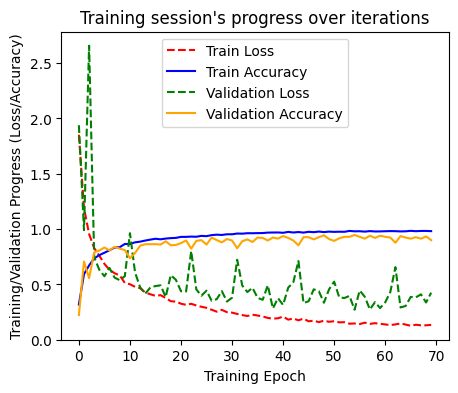

In [ ]:
plt.figure(figsize=(5, 4))
plt.plot(np.array(history.history['loss']), "r--", label = "Train Loss")
plt.plot(np.array(history.history['accuracy']), "b-", label = "Train Accuracy")
plt.plot(np.array(history.history['val_loss']), "g--", label = "Validation Loss")
plt.plot(np.array(history.history['val_accuracy']), "orange", label = "Validation Accuracy")
plt.title("Training session's progress over iterations")
plt.legend(loc='upper center')
plt.ylabel('Training/Validation Progress (Loss/Accuracy)')
plt.xlabel('Training Epoch')
plt.ylim(0)
plt.show()

In [ ]:
# Evaluate the model
loss, local_accuracy = model.evaluate(X_test, Y_test)
print(f'Loss: {loss}, Accuracy: {local_accuracy}')

29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9067 - loss: 0.4031
Loss: 0.41860005259513855, Accuracy: 0.9035476446151733


In [ ]:
label_classes = ["Walking", "Shuffling", "Upstairs", "Downstairs", "Standing", "Sitting", "Lying"]

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


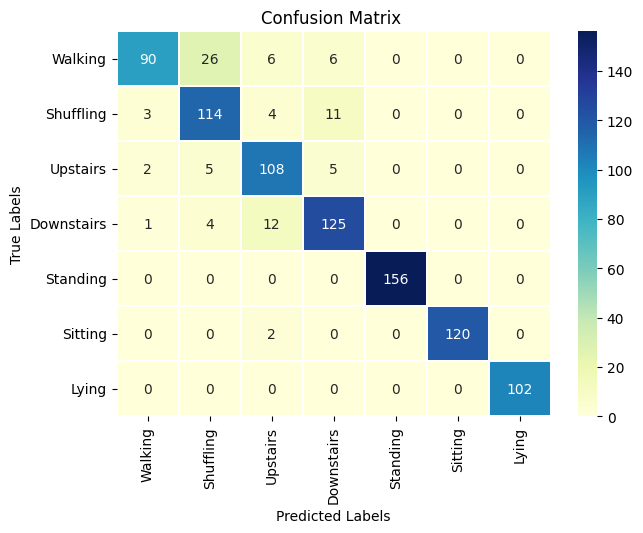

In [ ]:
max_test = Y_test if Y_test.ndim == 1 else np.argmax(Y_test, axis=1)
max_predictions = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(max_test, max_predictions)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', linewidths = 0.1, xticklabels=label_classes, yticklabels=label_classes)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix ')
plt.show()